# 06 — Comparación e interpretación de los modelos

**Escenario 4:** Efectividad de campañas de marketing

En este notebook se juntan los resultados de los tres enfoques (notebooks 03, 04 y 05) para compararlos y sacar conclusiones sobre el problema.

Como los tres modelos resuelven tareas distintas, no se pueden comparar con una sola métrica. La comparación se hace según **qué aporta cada uno** a la campaña de marketing.

## 1. Carga de resultados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

sns.set_theme(style="whitegrid", palette="deep")

with open("../data/processed/resultados_naive_bayes.json") as f:
    nb = json.load(f)
with open("../data/processed/resultados_pca.json", encoding="utf-8") as f:
    pca = json.load(f)
with open("../data/processed/resultados_monte_carlo.json", encoding="utf-8") as f:
    mc = json.load(f)

print("Resultados cargados:", nb["modelo"], "|", pca["modelo"], "|", mc["modelo"])

Resultados cargados: Gaussian Naive Bayes | PCA | Monte Carlo first-visit (on-policy, ε-greedy)


## 2. Resumen general de los tres enfoques

In [2]:
mc_agente = next(e for e in mc["comparacion_estrategias"] if e["estrategia"] == "Agente Monte Carlo")
mc_mejor_fija = max((e for e in mc["comparacion_estrategias"] if e["estrategia"] != "Agente Monte Carlo"),
                    key=lambda e: e["recompensa_promedio"])

resumen = pd.DataFrame([
    {"enfoque": "Supervisado", "algoritmo": "Gaussian Naive Bayes",
     "tarea": "Predecir si el cliente acepta (sí/no)",
     "usa y": "Sí (para entrenar)",
     "resultado principal": f"F1 = {nb['metricas_umbral_05']['f1']:.2f} | ROC-AUC = {nb['metricas_umbral_05']['roc_auc']:.2f} | Recall = {nb['metricas_umbral_05']['recall']:.2f}"},
    {"enfoque": "No supervisado", "algoritmo": "PCA",
     "tarea": "Reducir dimensiones y encontrar componentes principales",
     "usa y": "No (solo para interpretar)",
     "resultado principal": f"{pca['variables_originales']} → {pca['componentes_elegidos']} componentes ({pca['varianza_conservada_%']:.1f}% de varianza)"},
    {"enfoque": "Refuerzo", "algoritmo": "Monte Carlo (first-visit, ε-greedy)",
     "tarea": "Decidir cómo contactar a cada cliente",
     "usa y": "No (aprende de recompensas simuladas)",
     "resultado principal": f"{mc_agente['recompensa_promedio']:.2f} por cliente ({mc_agente['recompensa_promedio']/mc['recompensa_optima']*100:.0f}% del óptimo)"},
]).set_index("enfoque")
resumen

,algoritmo,tarea,usa y,resultado principal
enfoque,,,,
Supervisado,Gaussian Naive Bayes,Predecir si el cliente acepta (sí/no),Sí (para entrenar),F1 = 0.43 | ROC-AUC = 0.78 | Recall = 0.44
No supervisado,PCA,Reducir dimensiones y encontrar componentes pr...,No (solo para interpretar),41 → 22 componentes (80.5% de varianza)
Refuerzo,"Monte Carlo (first-visit, ε-greedy)",Decidir cómo contactar a cada cliente,No (aprende de recompensas simuladas),5.49 por cliente (95% del óptimo)


## 3. Aprendizaje supervisado: Naive Bayes vs modelo base

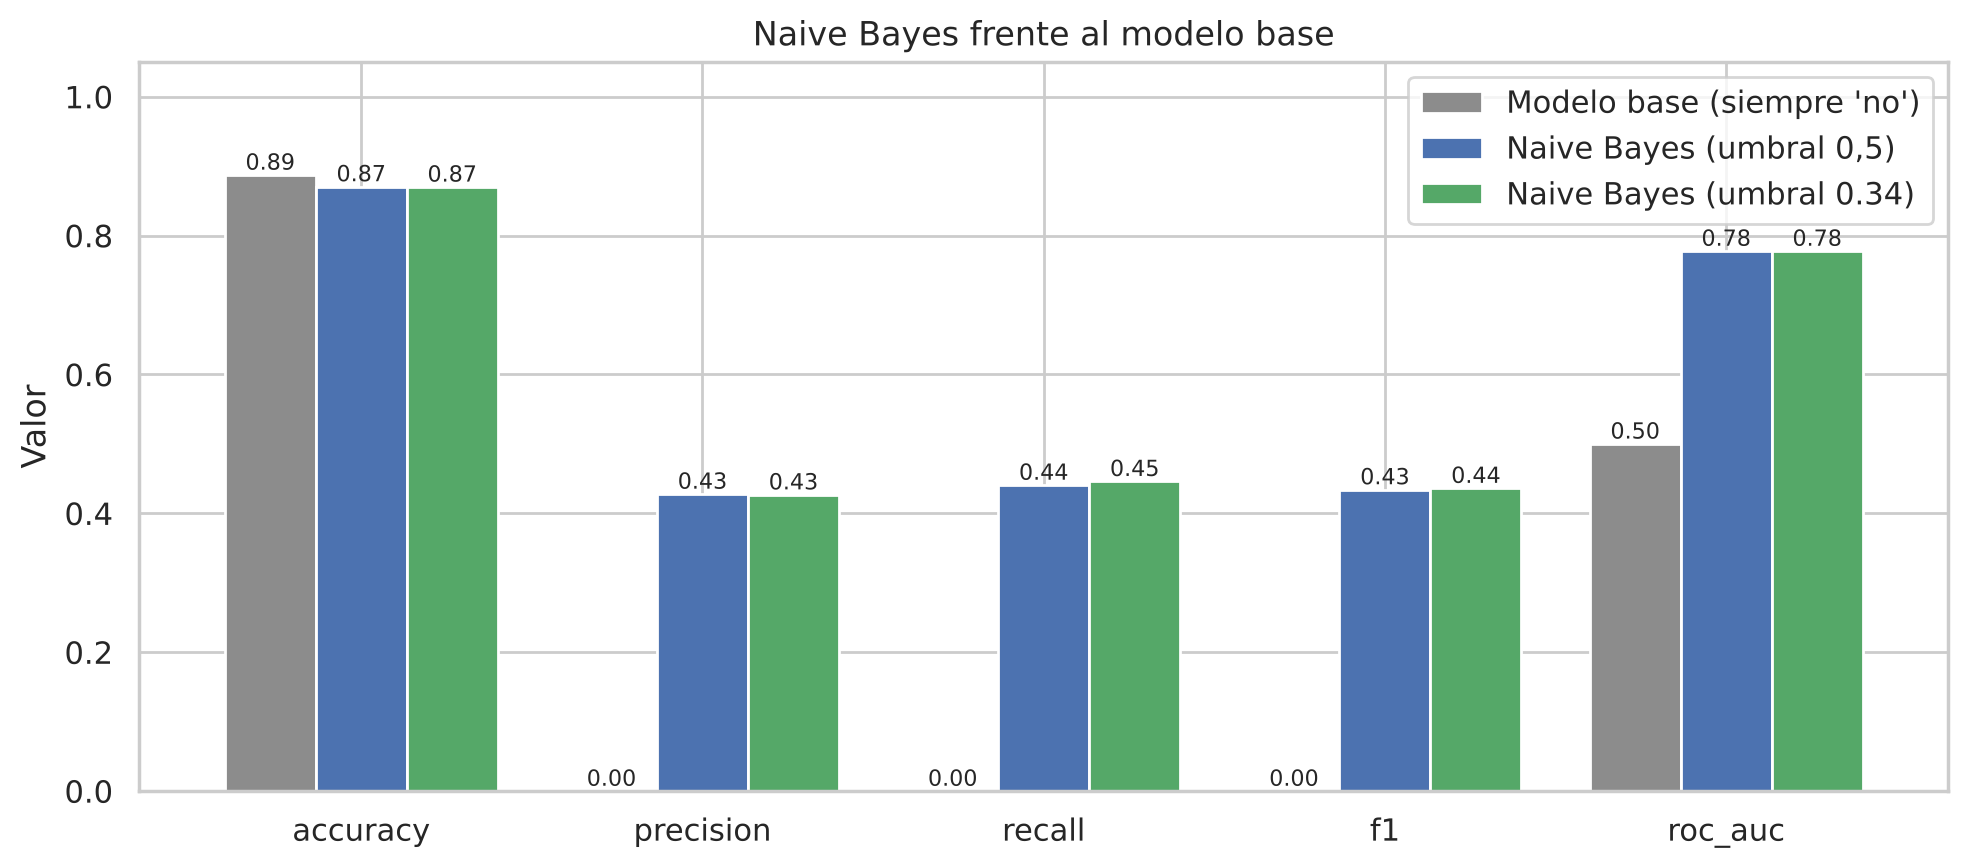

,Modelo base (siempre 'no'),"Naive Bayes (umbral 0,5)",Naive Bayes (umbral 0.34)
accuracy,0.8873,0.8706,0.8701
precision,0.0000,0.4278,0.4268
recall,0.0000,0.4407,0.4461
f1,0.0000,0.4342,0.4362
roc_auc,0.5000,0.7777,0.7777


In [3]:
met = ["accuracy", "precision", "recall", "f1", "roc_auc"]
tabla_nb = pd.DataFrame({
    "Modelo base (siempre 'no')": [nb["baseline_accuracy"], 0, 0, 0, 0.5],
    "Naive Bayes (umbral 0,5)": [nb["metricas_umbral_05"][m] for m in met],
    f"Naive Bayes (umbral {nb['umbral_optimo']:.2f})": [nb["metricas_umbral_optimo"][m] for m in met],
}, index=met)

fig, ax = plt.subplots(figsize=(10, 4.5))
tabla_nb.plot(kind="bar", ax=ax, color=["#8C8C8C", "#4C72B0", "#55A868"], width=0.8)
ax.set_title("Naive Bayes frente al modelo base")
ax.set_ylabel("Valor")
ax.set_xticklabels(met, rotation=0)
ax.set_ylim(0, 1.05)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()
tabla_nb.round(4)

## 4. Aprendizaje no supervisado: PCA y su efecto en Naive Bayes

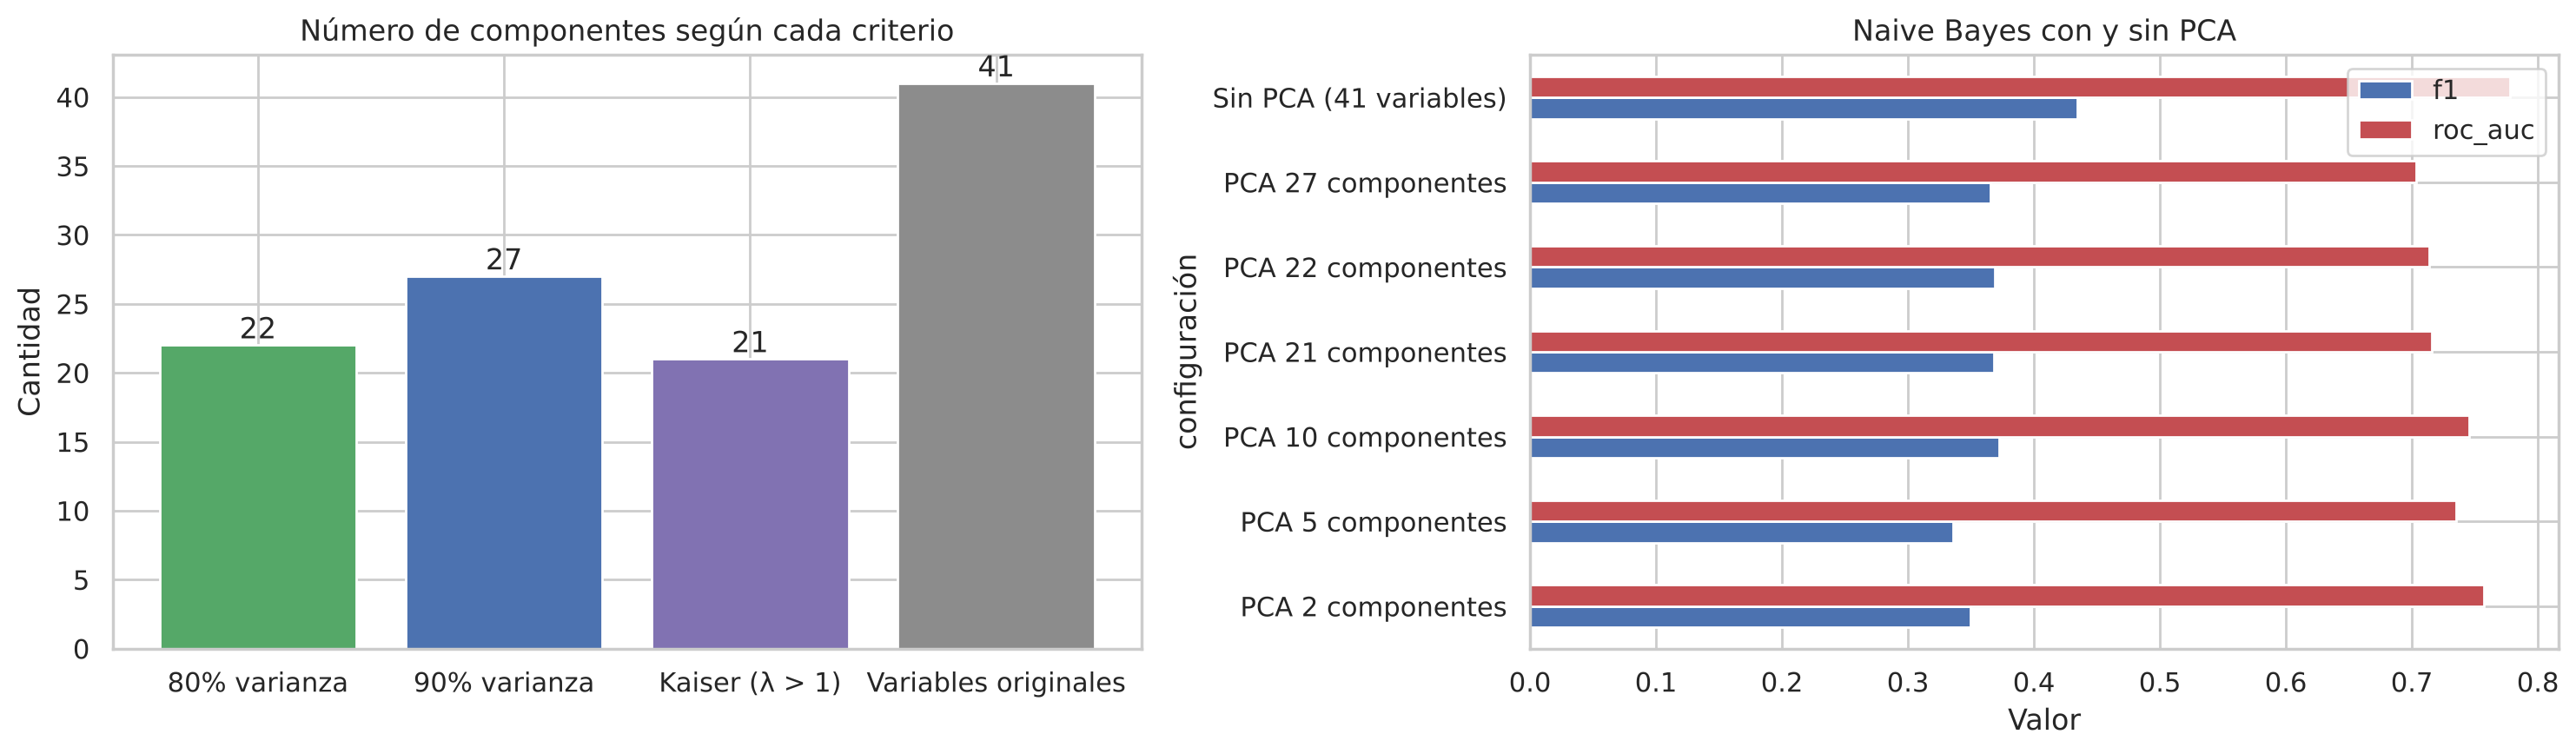

,precision,recall,f1,roc_auc
configuración,,,,
PCA 2 componentes,0.5707,0.2522,0.3498,0.7571
PCA 5 componentes,0.5589,0.2403,0.3361,0.7354
PCA 10 componentes,0.5037,0.2953,0.3723,0.7452
PCA 21 componentes,0.3316,0.4138,0.3682,0.7159
PCA 22 componentes,0.3372,0.4073,0.3690,0.7138
PCA 27 componentes,0.3211,0.4235,0.3652,0.7034
Sin PCA (41 variables),0.4278,0.4407,0.4342,0.7777


In [4]:
tabla_pca_nb = pd.DataFrame(pca["naive_bayes_con_pca"]).set_index("configuración")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
criterios = pd.Series({"80% varianza": pca["componentes_80"], "90% varianza": pca["componentes_90"],
                       "Kaiser (λ > 1)": pca["componentes_kaiser"], "Variables originales": pca["variables_originales"]})
axes[0].bar(criterios.index, criterios.values, color=["#55A868", "#4C72B0", "#8172B2", "#8C8C8C"])
for i, v in enumerate(criterios.values):
    axes[0].text(i, v + 0.5, str(v), ha="center")
axes[0].set_title("Número de componentes según cada criterio")
axes[0].set_ylabel("Cantidad")

tabla_pca_nb[["f1", "roc_auc"]].plot(kind="barh", ax=axes[1], color=["#4C72B0", "#C44E52"])
axes[1].set_title("Naive Bayes con y sin PCA")
axes[1].set_xlabel("Valor")
plt.tight_layout()
plt.show()
tabla_pca_nb

## 5. Aprendizaje por refuerzo: Monte Carlo vs estrategias fijas

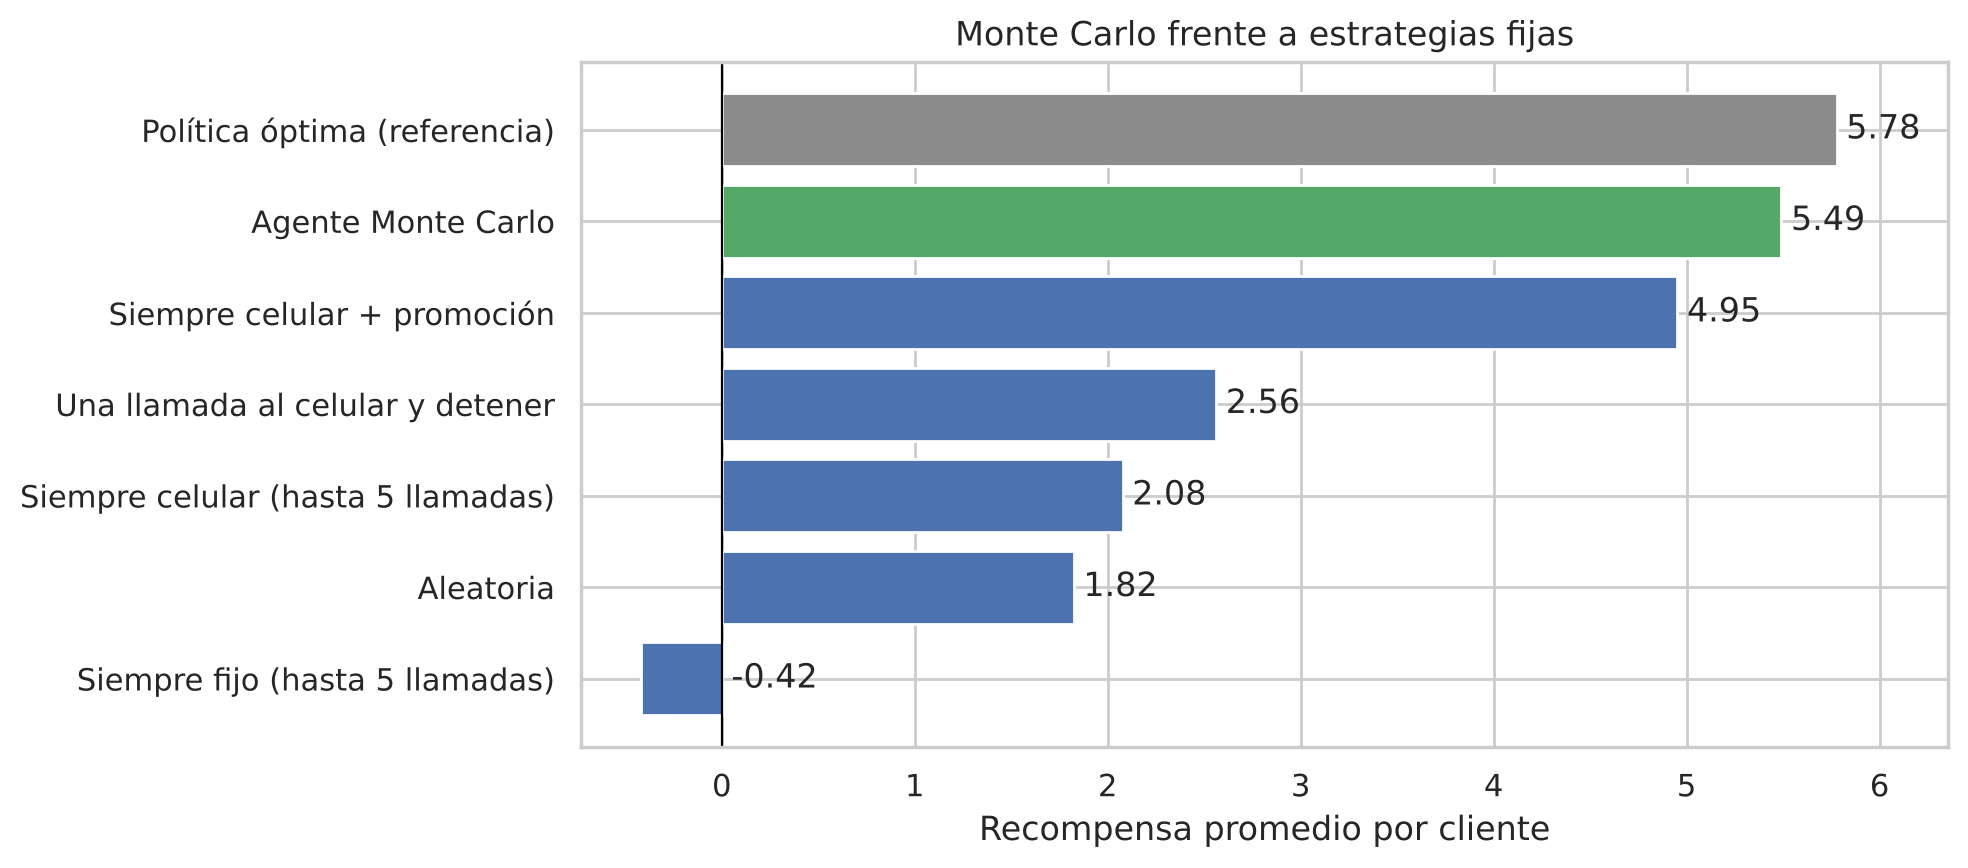

,recompensa_promedio,conversion_%,llamadas_por_cliente
estrategia,,,
Siempre fijo (hasta 5 llamadas),-0.418,18.370,3.386
Aleatoria,1.824,18.760,1.663
Siempre celular (hasta 5 llamadas),2.077,33.555,3.082
Una llamada al celular y detener,2.562,13.970,1.000
Siempre celular + promoción,4.952,45.780,2.843
Agente Monte Carlo,5.491,38.510,2.351
Política óptima (referencia),5.777,NaN,NaN


In [5]:
tabla_mc = pd.DataFrame(mc["comparacion_estrategias"]).set_index("estrategia")
tabla_mc.loc["Política óptima (referencia)", "recompensa_promedio"] = mc["recompensa_optima"]
tabla_mc = tabla_mc.sort_values("recompensa_promedio")

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["#55A868" if i == "Agente Monte Carlo" else "#8C8C8C" if "óptima" in i else "#4C72B0" for i in tabla_mc.index]
ax.barh(tabla_mc.index, tabla_mc["recompensa_promedio"], color=colores)
for i, v in enumerate(tabla_mc["recompensa_promedio"]):
    ax.text(max(v, 0) + 0.05, i, f"{v:.2f}", va="center", ha="left")
ax.set_xlim(right=tabla_mc["recompensa_promedio"].max() * 1.1)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Recompensa promedio por cliente")
ax.set_title("Monte Carlo frente a estrategias fijas")
plt.tight_layout()
plt.show()
tabla_mc.round(3)

In [6]:
politica = pd.DataFrame(mc["politica"]).T
politica.columns = [f"{k} llamadas" for k in politica.columns]
politica.index.name = "perfil"
politica

,0 llamadas,1 llamadas,2 llamadas,3 llamadas,4 llamadas
perfil,,,,,
nuevo,celular_promo,celular_promo,celular_promo,detener,detener
fallo_previo,celular_promo,celular_promo,fijo,fijo,celular_promo
receptivo,celular,celular,celular,celular_promo,celular_promo
exito_previo,fijo,fijo,fijo,celular_promo,celular


## 6. ¿Qué aporta cada enfoque a la campaña?

| Pregunta del banco | Enfoque que la responde | Respuesta según los resultados |
|---|---|---|
| ¿A **qué clientes** conviene llamar? | Supervisado (Naive Bayes) | El modelo identifica a 44% de los clientes que aceptarían, y de cada 10 clientes que recomienda llamar acepta casi 4 (contra 1 de cada 10 llamando al azar). |
| ¿Qué **factores** explican las diferencias entre clientes? | No supervisado (PCA) | El factor principal (PC1) es el contexto económico junto con el historial de contactos. Le siguen el perfil personal (edad, estado civil) y el canal o mes de la campaña. |
| ¿**Cómo** contactar a cada cliente y **cuándo** dejar de insistir? | Refuerzo (Monte Carlo) | Usar el fijo y sin descuento con clientes que ya aceptaron antes, el celular con estudiantes y jubilados, y promoción con los clientes nuevos, dejando de llamarlos después de 3 intentos. |

Los tres enfoques se complementan: el supervisado **predice**, el no supervisado **explica la estructura** de los datos y el de refuerzo **decide una estrategia**.

## 7. Comparación de características de los algoritmos

| Característica | Naive Bayes | PCA | Monte Carlo |
|---|---|---|---|
| Tipo de aprendizaje | Supervisado | No supervisado | Por refuerzo |
| Necesita etiquetas | Sí | No | No (usa recompensas) |
| Datos que usa | `bank_clean.csv` | `bank_scaled.csv` | Entorno simulado con probabilidades del dataset |
| Necesita escalado | No (se usó por consistencia) | Sí, es obligatorio | No |
| Hiperparámetros principales | `var_smoothing`, umbral | Número de componentes | γ, ε, número de episodios |
| Tiempo de entrenamiento | Muy rápido (< 1 s) | Muy rápido (< 1 s) | Más lento (~10 s por cada 100.000 episodios) |
| Interpretabilidad | Alta (probabilidades y medias por clase) | Media (cada componente mezcla varias variables) | Alta (tabla de política por estado) |
| Principal limitación | Supone variables independientes | Solo captura relaciones lineales | Alta varianza y depende de los supuestos del entorno |

## 8. Limitaciones generales

1. **Desbalance de clases:** solo el 11,3% de los clientes acepta, lo que hace difícil que el modelo supervisado detecte a todos los que aceptarían (recall de 0,44).
2. **Supuesto de independencia de Naive Bayes:** no se cumple por las variables económicas muy correlacionadas. Se intentó resolver con PCA, pero el resultado empeoró porque PCA no está pensado para separar clases.
3. **Muchas variables binarias:** el One-Hot Encoding generó muchas columnas binarias. Esto afecta tanto a GaussianNB (que supone distribuciones normales) como a PCA (que funciona mejor con variables continuas).
4. **Supuestos del entorno de refuerzo:** la ganancia, los costos, la penalización y el efecto de la promoción no vienen del dataset. Si estos valores cambian, la estrategia óptima también puede cambiar.
5. **Datos de 2008-2010:** las campañas son de un banco de Portugal durante la crisis financiera, así que los resultados pueden no aplicar igual en otro país o en otra época (por ejemplo en Bolivia).

## 9. Conclusiones

1. Se aplicaron los tres enfoques de Machine Learning al problema de la efectividad de campañas de marketing usando el dataset Bank Marketing (41.176 registros después de la limpieza).
2. **Naive Bayes** logró un F1 de 0,43 y un ROC-AUC de 0,78. Aunque su accuracy (87%) es un poco menor que la del modelo base (88,7%), sí detecta a los clientes interesados, y llamando solo a los que recomienda la tasa de éxito pasa de 11% a cerca de 43%.
3. **PCA** redujo las 41 variables a 22 componentes conservando el 80,5% de la información. El primer componente resume el contexto económico y es el que más se relaciona con la aceptación: en su quintil más bajo acepta el 30% de los clientes y en el más alto solo el 4%.
4. **Monte Carlo** aprendió una estrategia de contacto que gana 5,49 por cliente, más que cualquier estrategia fija y cerca del 95% de la óptima teórica. También mostró que conseguir más conversiones no siempre significa ganar más.
5. En los tres enfoques aparecieron los mismos factores importantes: **el historial de contactos anteriores, el canal (celular), el contexto económico y el perfil del cliente** (estudiantes y jubilados). Esto le da coherencia a los resultados.

## 10. Posibles mejoras

1. Probar técnicas para el desbalance, como sobremuestreo (SMOTE) o pesos por clase.
2. Comparar Naive Bayes con otros clasificadores (regresión logística, árboles de decisión) para saber si el problema está en el modelo o en los datos.
3. Usar **CategoricalNB** para las variables categóricas y **GaussianNB** para las continuas, en lugar de usar solo GaussianNB con todas.
4. Hacer un entorno de refuerzo más completo, agregando al estado el mes o el contexto económico, y comparar Monte Carlo con SARSA o Q-Learning.
5. Usar las probabilidades de Naive Bayes como parte del estado del agente de refuerzo, para que las decisiones de contacto se basen en la predicción de cada cliente.